## Check for similiarity in datasets

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer, util

EXPGUARD = "../../data_ood_translated/expguard_finance_test_de_with_correction.jsonl"
POLYGUARD = "../../data_ood_translated/polyguard_finance_test_de.jsonl"
TEST  = "../../data_in/test.jsonl"
VAL  = "../../data_in/validation.jsonl"
TRAINING = "../../data_in/train.jsonl"


expguard = pd.read_json(EXPGUARD, lines=True)
polyguard = pd.read_json(POLYGUARD, lines=True)
v3 = pd.read_json(TEST, lines=True)
v35 = pd.read_json(TRAINING, lines=True)
val = pd.read_json(VAL, lines=True)

datasets = {
    "Trainingsdaten": v35,
    "ExpGuard":  expguard,
    "PolyGuard": polyguard,
}

,count,mean,std,min,25%,50%,75%,max
dataset,,,,,,,,
ExpGuard,964.0,24.7,19.9,6.0,13.0,19.0,28.0,145.0
PolyGuard,994.0,97.4,35.6,37.0,71.0,88.0,117.0,276.0
Trainingsdaten,1643.0,51.2,133.6,1.0,10.0,15.0,26.0,2534.0


prompt_label,safe,unsafe
dataset,,
ExpGuard,18.0,19.0
PolyGuard,71.0,116.0
Trainingsdaten,12.0,15.0


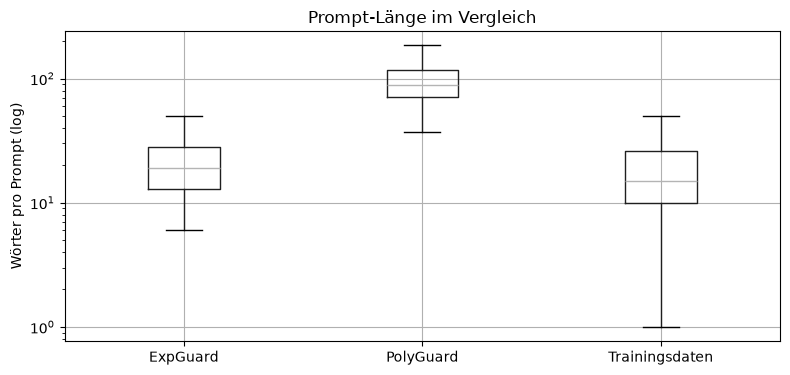

In [2]:
frames = []
for name, df in datasets.items():
    d = df[["prompt", "prompt_label"]].copy()
    d = d[d["prompt"].notna() & (d["prompt"].str.strip() != "") & (d["prompt"] != "REDACTED")]
    d["dataset"] = name
    d["zeichen"] = d["prompt"].str.len()
    d["woerter"] = d["prompt"].str.split().str.len()
    frames.append(d)

laengen = pd.concat(frames, ignore_index=True)

# Kennzahlen pro Datensatz
display(laengen.groupby("dataset")["woerter"].describe(percentiles=[.25, .5, .75]).round(1))

# Median getrennt nach Label
display(laengen.groupby(["dataset", "prompt_label"])["woerter"].median().unstack())

# Boxplot
fig, ax = plt.subplots(figsize=(8, 4))
laengen.boxplot(column="woerter", by="dataset", ax=ax, showfliers=False)
ax.set_yscale("log")
ax.set_ylabel("Wörter pro Prompt (log)")
ax.set_xlabel("")
ax.set_title("Prompt-Länge im Vergleich")
plt.suptitle("")
plt.tight_layout()
plt.show()

In [3]:
model = SentenceTransformer("BAAI/bge-m3")
model.max_seq_length = 8192 

In [16]:
tok = model.tokenizer
limit = model.max_seq_length  # 128

for name, df in {"Training": v35, "Val": val, "Test": v3,
                 "ExpGuard": expguard, "PolyGuard": polyguard}.items():
    n_tok = df["prompt"].map(lambda p: len(tok(p, add_special_tokens=True)["input_ids"]))
    print(f"{name:10s} Median {n_tok.median():5.0f}  |  Max {n_tok.max():6.0f}  |  > {limit} Token: {(n_tok > limit).mean():.1%}")

Training   Median    26  |  Max   3660  |  > 8192 Token: 0.0%
Val        Median    65  |  Max   2616  |  > 8192 Token: 0.0%
Test       Median    42  |  Max   1483  |  > 8192 Token: 0.0%
ExpGuard   Median    37  |  Max    261  |  > 8192 Token: 0.0%
PolyGuard  Median   173  |  Max    604  |  > 8192 Token: 0.0%


In [4]:
import os
import torch
from sentence_transformers import util

os.makedirs("embeddings", exist_ok=True)

def encode(texts, batch_size=32):
    return model.encode(texts.tolist(), batch_size=batch_size, convert_to_tensor=True,
                        normalize_embeddings=True, show_progress_bar=True)

def encode_mit_cache(name, texts, batch_size=32):
    """Kodiert einmal und speichert das Ergebnis. Beim nächsten Mal wird nur geladen."""
    pfad = f"embeddings/{name}.pt"
    if os.path.exists(pfad):
        print(f"{name}: aus Datei geladen")
        return torch.load(pfad)
    emb = encode(texts, batch_size=batch_size)
    torch.save(emb, pfad)
    return emb

def nn_sim(query, reference, block=1000):
    """Für jeden Query-Prompt: Ähnlichkeit zum ähnlichsten Referenz-Prompt (paketweise)."""
    besten = []
    for start in range(0, len(query), block):
        sims = util.cos_sim(query[start:start + block], reference)
        besten.append(sims.max(dim=1).values.cpu())
    return torch.cat(besten).numpy()

In [12]:
emb_v35 = encode_mit_cache("v35", v35["prompt"], batch_size=2)

v35: aus Datei geladen


In [13]:
emb_pol = encode_mit_cache("polyguard", polyguard["prompt"])
polyguard["nn_sim"] = nn_sim(emb_pol, emb_v35)

polyguard: aus Datei geladen


In [14]:
emb_exp = encode_mit_cache("expguard", expguard["prompt"])
expguard["nn_sim"] = nn_sim(emb_exp, emb_v35)

expguard: aus Datei geladen


In [10]:
import gc

gc.collect()
torch.mps.empty_cache()

emb_val = encode_mit_cache("v3_val", val["prompt"], batch_size=2)
val["nn_sim"] = nn_sim(emb_val, emb_v35)
v3["nn_sim"] = nn_sim(emb_v3, emb_v35)

v3_val: aus Datei geladen


In [15]:
vergleich = pd.DataFrame({
    "Val (ID)":  val["nn_sim"].describe(),
    "Test (ID)": v3["nn_sim"].describe(),
    "ExpGuard":  expguard["nn_sim"].describe(),
    "PolyGuard": polyguard["nn_sim"].describe(),
}).round(3)
display(vergleich)

,Val (ID),Test (ID),ExpGuard,PolyGuard
count,1700.000,2364.000,964.000,994.000
mean,0.608,0.614,0.559,0.543
std,0.073,0.073,0.047,0.031
min,0.401,0.373,0.428,0.442
25%,0.560,0.566,0.526,0.522
50%,0.595,0.601,0.557,0.543
75%,0.642,0.655,0.589,0.564
max,0.987,0.956,0.768,0.673


In [17]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

ergebnisse = []
for name, df in [("ExpGuard", expguard), ("PolyGuard", polyguard)]:
    id_werte  = v3["nn_sim"].to_numpy()
    ood_werte = df["nn_sim"].to_numpy()

    # 1) Mann-Whitney-U: Liegen die v3-Werte systematisch höher?
    _, p = mannwhitneyu(id_werte, ood_werte, alternative="greater")

    # 2) AUROC: Wie gut trennt die Ähnlichkeit v3 (=1) von OOD (=0)?
    y      = np.r_[np.ones(len(id_werte)), np.zeros(len(ood_werte))]
    scores = np.r_[id_werte, ood_werte]
    auroc  = roc_auc_score(y, scores)

    ergebnisse.append({"Datensatz": name, "Median OOD": np.median(ood_werte),
                       "p-Wert": p, "AUROC": auroc})

display(pd.DataFrame(ergebnisse).round({"Median OOD": 3, "AUROC": 3}))

,Datensatz,Median OOD,p-Wert,AUROC
0,ExpGuard,0.557,0.0,0.737
1,PolyGuard,0.543,0.0,0.832


In [ ]:
import numpy as np

emb_train = emb_v35.cpu().numpy() if hasattr(emb_v35, "cpu") else emb_v35
rng = np.random.default_rng(42)

# 1) Untergrenze: zufällige Paare aus dem Training
i = rng.integers(0, len(emb_train), 10_000)
j = rng.integers(0, len(emb_train), 10_000)
mask = i != j
zufall = (emb_train[i[mask]] * emb_train[j[mask]]).sum(axis=1)
print("Zufällige Paare:", np.percentile(zufall, [25, 50, 75]).round(3))

# 2) Wie nah sind sich Trainingsprompts untereinander? (nächster Nachbar ohne sich selbst)
sim = emb_train @ emb_train.T
np.fill_diagonal(sim, -1)
print("Training ↔ Training (NN):", np.percentile(sim.max(axis=1), [25, 50, 75]).round(3))

import pandas as pd

print("Zufällige Paare:")
print(pd.Series(zufall).describe().round(3))

print("\nTraining ↔ Training (NN):")
print(pd.Series(sim.max(axis=1)).describe().round(3))

Zufällige Paare: [0.343 0.389 0.44 ]
Training ↔ Training (NN): [0.65 0.72 0.8 ]
